<a href="https://colab.research.google.com/github/juvowen/AlgoTrading/blob/main/LSTMForcasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

HYPOTHESIS : Forecast the next trading day using golds price and test a trading strategy.

An LSTM trained on historical gold prices can learn temporal patterns that improve next-day price forecasts relative to a simple baseline. If its forecasts contain information about future returns, we may be able to use them to construct a profitable long/short strategy after transaction costs.

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = yf.download(
    "GC=F",
    period="10y",
    interval="1d",
    auto_adjust=False,
    progress=False
)

if df.empty:
    raise ValueError("No data downloaded from Yahoo Finance.")

# Handle different yfinance column formats.
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

required_columns = ["Open", "High", "Low", "Close", "Volume"]

missing = set(required_columns) - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df = df[required_columns].copy()
df = df.sort_index()
df = df[~df.index.duplicated(keep="last")]

# Remove invalid price observations.
df = df.dropna(subset=["Open", "High", "Low", "Close"])
df = df[(df[["Open", "High", "Low", "Close"]] > 0).all(axis=1)]

print("Rows:", len(df))
display(df.tail())

Rows: 2514


Price,Open,High,Low,Close,Volume
Date,,,,,
2026-10-09,4159.700195,4233.700195,4156.100098,4216.299805,134612
2026-10-12,4220.799805,4242.299805,4178.100098,4190.600098,102772
2026-10-13,4195.500000,4224.799805,4169.700195,4177.299805,124779
2026-10-14,4184.200195,4193.500000,4095.000000,4107.899902,124779
2026-10-15,4192.100098,4193.899902,4172.899902,4177.299805,6328


In [ ]:
#cell b: engineering our features

# 1. Daily percentage return
df["Return_1d"] = df["Close"].pct_change()

# 2. Short-term realized volatility
df["Volatility_5d"] = (
    df["Return_1d"].rolling(5).std()
)

# 3. Longer-term realized volatility
df["Volatility_20d"] = (
    df["Return_1d"].rolling(20).std()
)

# 4. Volume relative to its recent average
volume_average = df["Volume"].rolling(20).mean()

df["Volume_Ratio"] = (
    df["Volume"] / volume_average.replace(0, np.nan)
)

# 5. Intraday range relative to closing price
df["Intraday_Range"] = (
    (df["High"] - df["Low"]) / df["Close"]
)

# 6. Return from open to close
df["Intraday_Return"] = (
    df["Close"] / df["Open"] - 1
)

# Our target: return from today's close to the NEXT close.
df["Target_Return"] = (
    df["Close"].pct_change().shift(-1)
)

features = [
    "Return_1d",
    "Volatility_5d",
    "Volatility_20d",
    "Volume_Ratio",
    "Intraday_Range",
    "Intraday_Return",
]

df = df.replace([np.inf, -np.inf], np.nan)

# Drop rows where features or the next-day target are unavailable.
df = df.dropna(subset=features + ["Target_Return"]).copy()

print("Feature columns:", features)
print("Dataset rows:", len(df))

display(df[features + ["Target_Return"]].tail())

Feature columns: ['Return_1d', 'Volatility_5d', 'Volatility_20d', 'Volume_Ratio', 'Intraday_Range', 'Intraday_Return']
Dataset rows: 2493


Price,Return_1d,Volatility_5d,Volatility_20d,Volume_Ratio,Intraday_Range,Intraday_Return,Target_Return
Date,,,,,,,
2026-10-08,0.003936,0.008076,0.010504,0.952338,0.010248,0.004131,0.014265
2026-10-09,0.014265,0.009519,0.011168,0.878711,0.018405,0.013607,-0.006095
2026-10-12,-0.006095,0.010226,0.010923,0.684662,0.015320,-0.007155,-0.003174
2026-10-13,-0.003174,0.009850,0.010911,0.837195,0.013190,-0.004338,-0.016614
2026-10-14,-0.016614,0.011515,0.010840,0.873625,0.023978,-0.018235,0.016894


In [ ]:
#cell c:

LOOKBACK = 60

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

if train_end <= LOOKBACK or val_end <= train_end:
    raise ValueError("Not enough observations for this split.")

# Fit feature scaling only on the training period.
feature_scaler = StandardScaler()
feature_scaler.fit(df[features].iloc[:train_end])

scaled_features = feature_scaler.transform(
    df[features]
).astype(np.float32)

# Scale the target separately.
target_scaler = StandardScaler()
target_scaler.fit(
    df[["Target_Return"]].iloc[:train_end]
)

scaled_target = target_scaler.transform(
    df[["Target_Return"]]
).flatten().astype(np.float32)

print("Training boundary:", df.index[train_end])
print("Validation boundary:", df.index[val_end])
print("Number of features:", len(features))

Training boundary: 2023-10-25 00:00:00
Validation boundary: 2025-04-22 00:00:00
Number of features: 6


In [ ]:
X = []
y = []
target_positions = []

for i in range(LOOKBACK - 1, n - 1):

    # Features through day i, inclusive.
    X.append(
        scaled_features[i - LOOKBACK + 1:i + 1]
    )

    # Target return from day i's close to day i+1's close.
    y.append(scaled_target[i])

    # Record the date of the actual target return.
    target_positions.append(i + 1)

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
target_positions = np.asarray(target_positions)

# Split by the date on which the target return is realized.
train_mask = target_positions < train_end

val_mask = (
    (target_positions >= train_end)
    & (target_positions < val_end)
)

test_mask = target_positions >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

test_positions = target_positions[test_mask]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (1685, 60, 6)
X_val: (374, 60, 6)
X_test: (374, 60, 6)


In [ ]:
#cell E: new lstm

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(LOOKBACK, len(features))),

    LSTM(64),

    Dropout(0.2),

    Dense(16, activation="relu"),

    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

model.summary()

Epoch 1/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 7s 55ms/step - loss: 1.0253 - val_loss: 1.2014
Epoch 2/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 1.0116 - val_loss: 1.2019
Epoch 3/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - loss: 1.0066 - val_loss: 1.2014
Epoch 4/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 1.0005 - val_loss: 1.2230
Epoch 5/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 1.0033 - val_loss: 1.2122
Epoch 6/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.9930 - val_loss: 1.2110
Epoch 7/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.9894 - val_loss: 1.2024
Epoch 8/50
53/53 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.9891 - val_loss: 1.2181


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,701 (225.40 KB)

 Trainable params: 19,233 (75.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 38,468 (150.27 KB)

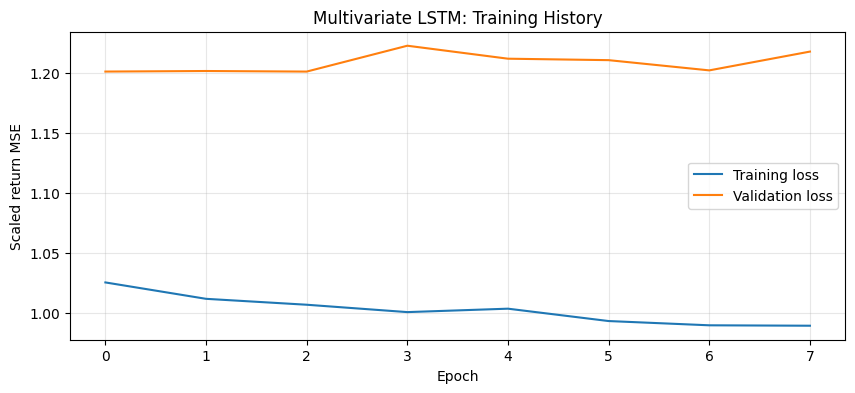

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Multivariate LSTM: Training History")
plt.xlabel("Epoch")
plt.ylabel("Scaled return MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
#actual prediction
predicted_scaled = model.predict(X_test, verbose=0)

predicted_returns = target_scaler.inverse_transform(
    predicted_scaled
).flatten()

actual_returns = target_scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

# target_positions points to the day on which the target return ends.
target_dates = df.index[test_positions]

# The signal is formed at the previous close.
previous_close = df["Close"].to_numpy()[test_positions - 1]
actual_close = df["Close"].to_numpy()[test_positions]

results = pd.DataFrame(
    {
        "Previous_Close": previous_close,
        "Actual_Close": actual_close,
        "Predicted_Return": predicted_returns,
        "Actual_Return": actual_returns,
    },
    index=target_dates
)

# Reconstruct a predicted price for visualization only.
results["Predicted_Close"] = (
    results["Previous_Close"]
    * (1 + results["Predicted_Return"])
)

display(results.tail(10))

,Previous_Close,Actual_Close,Predicted_Return,Actual_Return,Predicted_Close
Date,,,,,
2026-10-01,4186.700195,4202.299805,0.001424,0.003726,4192.663365
2026-10-02,4202.299805,4162.299805,0.001363,-0.009519,4208.027703
2026-10-05,4162.299805,4156.799805,0.001307,-0.001321,4167.738982
2026-10-06,4156.799805,4187.100098,0.001159,0.007289,4161.619321
2026-10-07,4187.100098,4140.700195,0.000561,-0.011082,4189.448058
2026-10-08,4140.700195,4157.000000,0.000336,0.003936,4142.092669
2026-10-09,4157.000000,4216.299805,0.000354,0.014265,4158.469810
2026-10-12,4216.299805,4190.600098,0.000012,-0.006095,4216.351575
2026-10-13,4190.600098,4177.299805,0.000067,-0.003174,4190.879351


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

lstm_mae = mean_absolute_error(
    results["Actual_Return"],
    results["Predicted_Return"]
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        results["Actual_Return"],
        results["Predicted_Return"]
    )
)

# Benchmark: predict zero return every day.
zero_mae = mean_absolute_error(
    results["Actual_Return"],
    np.zeros(len(results))
)

zero_rmse = np.sqrt(
    mean_squared_error(
        results["Actual_Return"],
        np.zeros(len(results))
    )
)

print(f"LSTM return MAE: {lstm_mae:.6f}")
print(f"Zero-return MAE: {zero_mae:.6f}")
print(f"LSTM return RMSE: {lstm_rmse:.6f}")
print(f"Zero-return RMSE: {zero_rmse:.6f}")

direction_accuracy = np.mean(
    (results["Predicted_Return"] > 0)
    == (results["Actual_Return"] > 0)
)

print(f"Directional accuracy: {direction_accuracy:.2%}")

LSTM return MAE: 0.011824
Zero-return MAE: 0.011786
LSTM return RMSE: 0.016518
Zero-return RMSE: 0.016487
Directional accuracy: 47.06%


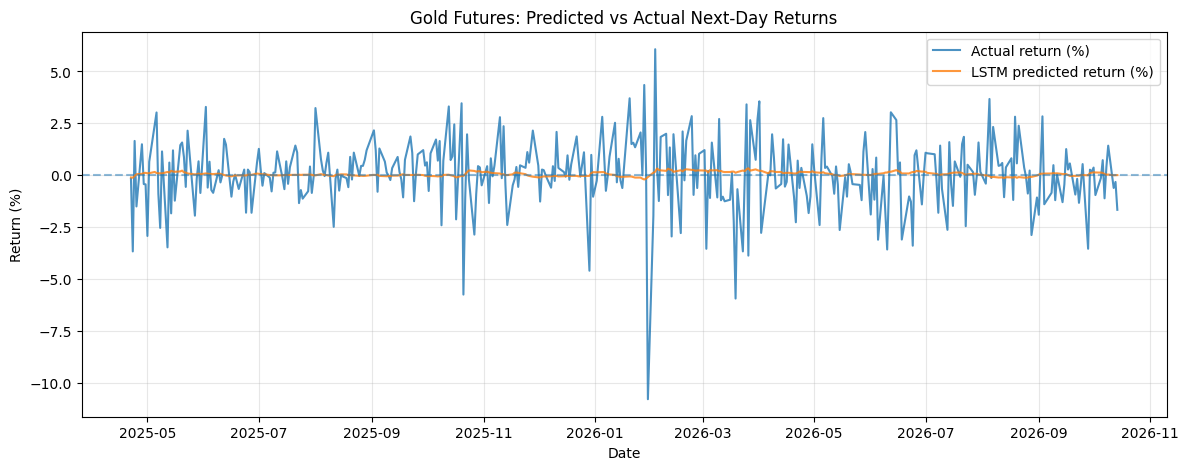

In [ ]:
#cell h
plt.figure(figsize=(14, 5))

plt.plot(
    results.index,
    results["Actual_Return"] * 100,
    label="Actual return (%)",
    alpha=0.8
)

plt.plot(
    results.index,
    results["Predicted_Return"] * 100,
    label="LSTM predicted return (%)",
    alpha=0.8
)

plt.axhline(0, linestyle="--", alpha=0.5)

plt.title("Gold Futures: Predicted vs Actual Next-Day Returns")
plt.xlabel("Date")
plt.ylabel("Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
TRADE_THRESHOLD = 0.001  # 0.10% predicted return

results["Signal"] = np.select(
    [
        results["Predicted_Return"] > TRADE_THRESHOLD,
        results["Predicted_Return"] < -TRADE_THRESHOLD,
    ],
    [1, -1],
    default=0
)

# Position change determines the estimated trading cost.
previous_positions = np.r_[
    0,
    results["Signal"].to_numpy()[:-1]
]

results["Position_Change"] = np.abs(
    results["Signal"].to_numpy() - previous_positions
)

COST_PER_UNIT = 0.0005

results["Trading_Cost"] = (
    results["Position_Change"] * COST_PER_UNIT
)

results["Strategy_Return"] = (
    results["Signal"] * results["Actual_Return"]
    - results["Trading_Cost"]
)

results["Strategy_Equity"] = (
    1 + results["Strategy_Return"]
).cumprod()

results["Buy_Hold_Equity"] = (
    1 + results["Actual_Return"]
).cumprod()

print(
    "Strategy total return:",
    f"{results['Strategy_Equity'].iloc[-1] - 1:.2%}"
)

print(
    "Buy-and-hold return:",
    f"{results['Buy_Hold_Equity'].iloc[-1] - 1:.2%}"
)

Strategy total return: 1.72%
Buy-and-hold return: 19.93%
